# 0. Representation — `0.1 + 0.2` is not `0.3`

**The lie.** *"The numbers I type are the numbers the machine stores."*

Floating point is a finite set of points on the real line. Every decimal you
type is first rounded to the nearest representable point, and that rounding
happens *before* any arithmetic. This notebook shows the gap.

## The setup

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from pathlib import Path

matplotlib.rcParams["figure.dpi"] = 110
FIG = Path("../figures")
FIG.mkdir(exist_ok=True)
rng = np.random.default_rng(0)

In [2]:
from fractions import Fraction

print("0.1 + 0.2      =", repr(0.1 + 0.2))
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3)
print("0.1 + 0.2 as exact rational:", Fraction(0.1 + 0.2))

0.1 + 0.2      = 0.30000000000000004
0.1 + 0.2 == 0.3 ? False
0.1 + 0.2 as exact rational: 1351079888211149/4503599627370496


`Fraction(0.1)` is the *true* value of the double nearest to `0.1` — 55
significant bits of a binary fraction, nowhere near `1/10`.

In [3]:
print("Fraction(0.1) =", Fraction(0.1))
print("1/10          =", Fraction(1, 10))
print("stored - 1/10 =", float(Fraction(0.1) - Fraction(1, 10)))

Fraction(0.1) = 3602879701896397/36028797018963968
1/10          = 1/10
stored - 1/10 = 5.551115123125783e-18


## The reality

In [4]:
# The gap between neighbours is not fixed; it doubles at every power of two.
for x in [1.0, 2.0, 4.0, 1e6, 1e16]:
    print(f"x = {x:>10.1e}   ulp = {np.spacing(x):.3e}   relative gap = {np.spacing(x)/x:.3e}")

print()
print("0.1 + 0.2 prints as", format(0.1 + 0.2, ".17f"))
print("0.3        prints as", format(0.3, ".17f"))

x =    1.0e+00   ulp = 2.220e-16   relative gap = 2.220e-16
x =    2.0e+00   ulp = 4.441e-16   relative gap = 2.220e-16
x =    4.0e+00   ulp = 8.882e-16   relative gap = 2.220e-16
x =    1.0e+06   ulp = 1.164e-10   relative gap = 1.164e-16
x =    1.0e+16   ulp = 2.000e+00   relative gap = 2.000e-16

0.1 + 0.2 prints as 0.30000000000000004
0.3        prints as 0.29999999999999999


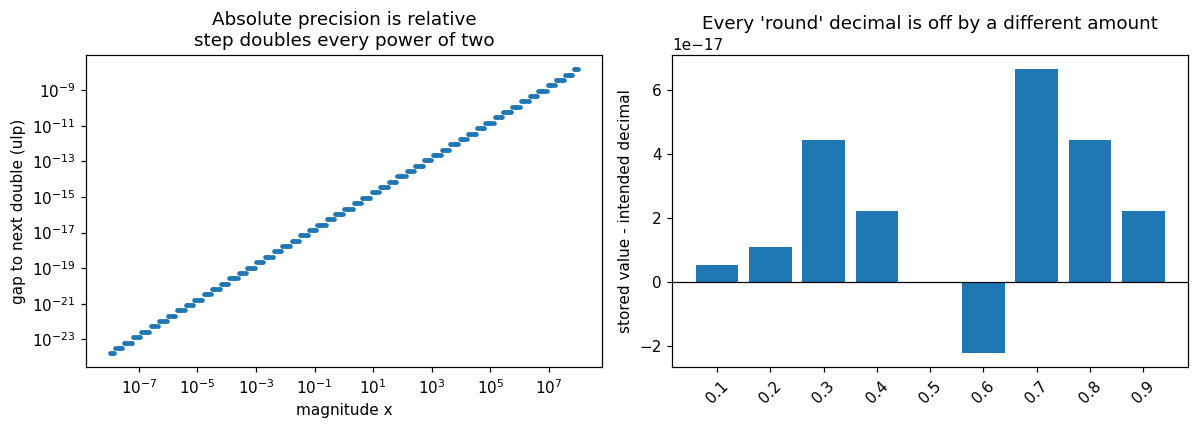

In [5]:
xs = np.arange(0.1, 1.0, 0.1)
err = np.array([float(Fraction(float(x)) - Fraction(x).limit_denominator(10**12)) for x in xs])

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

mag = np.logspace(-8, 8, 400)
ax[0].loglog(mag, np.spacing(mag), "o", ms=2)
ax[0].set_xlabel("magnitude x")
ax[0].set_ylabel("gap to next double (ulp)")
ax[0].set_title("Absolute precision is relative\nstep doubles every power of two")

ax[1].bar([f"{x:.1f}" for x in xs], err)
ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("stored value - intended decimal")
ax[1].set_title("Every 'round' decimal is off by a different amount")
ax[1].tick_params(axis="x", rotation=45)

fig.tight_layout()
fig.savefig(FIG / "00_representable_gap.png", bbox_inches="tight")
plt.show()

## The rule

- A decimal literal is **rounded to the nearest double** first; the error is up
  to half an ulp *relative* to its size.
- There is no fixed absolute resolution. `1e16` has no room for `1.0`.
- `repr()` / `format(x, ".17g")` shows the true neighbour. `print(0.1)` lies
  prettily.

```python
# fragile
if x == 0.3: ...
# robust
import math
if math.isclose(x, 0.3, rel_tol=1e-12): ...
```

## Taking it further

- Goldberg, *What Every Computer Scientist Should Know About Floating-Point
  Arithmetic*, §1 (formats, relative error, ulps).
- `float.as_integer_ratio()` — inspect any float exactly.
- `math.ulp(x)` (3.9+) — the local gap without `numpy`.